In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, classification_report

In [2]:
df = pd.read_csv("diabetes.csv")
print("Dataset shape:", df.shape)
print(df.head())
print(df.info())
print("\nOutcome counts:\n", df['Outcome'].value_counts())

Dataset shape: (768, 9)
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   Pedigree  Age  Outcome  
0     0.627   50        1  
1     0.351   31        0  
2     0.672   32        1  
3     0.167   21        0  
4     2.288   33        1  
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Pregnancies    768 non-null    int64  
 1   Glucose        768 non-null    int64  
 2   BloodPressure  768 non-null    int64  
 3   SkinThickness  768 non-null    int64  
 4   Insulin      

In [3]:
# In this dataset, 0 in these columns means the value is missing
cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
df[cols] = df[cols].replace(0, np.nan)

# Replace missing values with the column mean
df[cols] = df[cols].fillna(df[cols].mean())

print("Missing values:\n", df.isnull().sum())

Missing values:
 Pregnancies      0
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
Pedigree         0
Age              0
Outcome          0
dtype: int64


In [4]:
X = df.drop('Outcome', axis=1)
y = df['Outcome']



In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

Train shape: (614, 8)
Test shape: (154, 8)


In [6]:
# KNN uses distance, so all features must be on the same scale
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [7]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
y_pred = knn.predict(X_test)

Confusion Matrix:
 [[74 25]
 [14 41]]


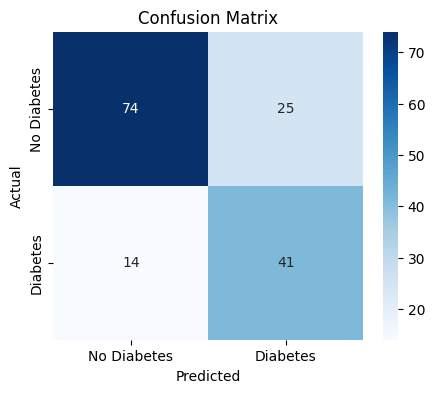

In [8]:
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", cm)

# Visualize confusion matrix
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Diabetes', 'Diabetes'],
            yticklabels=['No Diabetes', 'Diabetes'])
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [9]:
TN, FP, FN, TP = cm.ravel()
print("TP:", TP, " TN:", TN, " FP:", FP, " FN:", FN)

# Using formulas
accuracy = (TP + TN) / (TP + TN + FP + FN)
error_rate = (FP + FN) / (TP + TN + FP + FN)
precision = TP / (TP + FP)
recall = TP / (TP + FN)

print("\nAccuracy   :", round(accuracy, 4))
print("Error Rate :", round(error_rate, 4))
print("Precision  :", round(precision, 4))
print("Recall     :", round(recall, 4))

# Using sklearn (to verify)
print("\nsklearn Accuracy  :", round(accuracy_score(y_test, y_pred), 4))
print("sklearn Error Rate:", round(1 - accuracy_score(y_test, y_pred), 4))
print("sklearn Precision :", round(precision_score(y_test, y_pred), 4))
print("sklearn Recall    :", round(recall_score(y_test, y_pred), 4))

print("\nClassification Report:\n", classification_report(y_test, y_pred))

TP: 41  TN: 74  FP: 25  FN: 14

Accuracy   : 0.7468
Error Rate : 0.2532
Precision  : 0.6212
Recall     : 0.7455

sklearn Accuracy  : 0.7468
sklearn Error Rate: 0.2532
sklearn Precision : 0.6212
sklearn Recall    : 0.7455

Classification Report:
               precision    recall  f1-score   support

           0       0.84      0.75      0.79        99
           1       0.62      0.75      0.68        55

    accuracy                           0.75       154
   macro avg       0.73      0.75      0.73       154
weighted avg       0.76      0.75      0.75       154



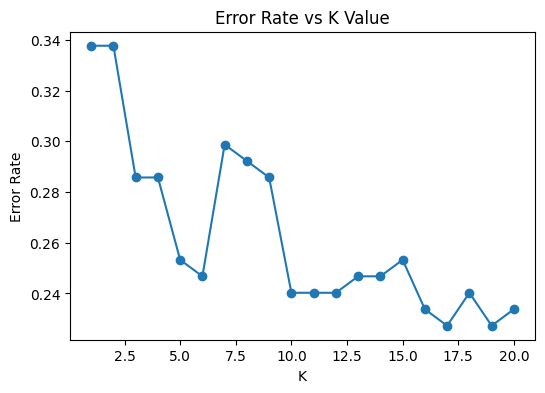

Best k: 17  Error rate: 0.2273


In [10]:
error_rates = []
for k in range(1, 21):
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)
    pred_k = model.predict(X_test)
    error_rates.append(np.mean(pred_k != y_test))

# Plot error rate vs k
plt.figure(figsize=(6,4))
plt.plot(range(1, 21), error_rates, marker='o')
plt.title('Error Rate vs K Value')
plt.xlabel('K')
plt.ylabel('Error Rate')
plt.show()

best_k = error_rates.index(min(error_rates)) + 1
print("Best k:", best_k, " Error rate:", round(min(error_rates), 4))